In [181]:
import pandas as pd
import numpy as np  

import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

import re

# Remove pandas display limits
pd.set_option("display.max_rows", 50)
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", None)

In [182]:
CAPACITY = 140
NOMINAL_TAPPING_WEIGHT = 122.5
T_POWER = 120

In [183]:
file_eaf_chem = 'data/eaf_final_chemical_measurements.csv'
file_temp = 'data/eaf_temp.csv'
# file_chem_ladle = 'data/lf_initial_chemical_measurements.csv'
file_ladle_tap = 'data/ladle_tapping.csv'
file_loading = 'data/basket_charged.csv'
file_materials = 'data/eaf_added_materials.csv'
file_power = 'data/eaf_transformer.csv'
file_inj = 'data/inj_mat.csv'
file_gas = 'data/eaf_gaslance_mat.csv'

In [184]:
df_temp = pd.read_csv(file_temp, decimal=",", parse_dates=True)
df_eaf_chem = pd.read_csv(file_eaf_chem, decimal=",", parse_dates=True)
df_loading = pd.read_csv(file_loading, decimal=",", parse_dates=True)
df_materials = pd.read_csv(file_materials, decimal=",", parse_dates=True)
df_power = pd.read_csv(file_power, decimal=",", parse_dates=True)
df_inj = pd.read_csv(file_inj, decimal=",", parse_dates=True)
df_gas = pd.read_csv(file_gas, decimal=",", parse_dates=True)
df_ladle_tap = pd.read_csv(file_ladle_tap, decimal=",", parse_dates=True)

dfs = {
    "df_temp": df_temp,
    "df_eaf_chem": df_eaf_chem,
    "df_loading": df_loading,
    "df_materials": df_materials,
    "df_power": df_power,
    "df_inj": df_inj,
    "df_gas": df_gas,
    "df_ladle_tap": df_ladle_tap
}

In [185]:
def duration_to_sec(duration: str) -> int:
    minutes, sec = duration.strip().split(":")
    minutes = minutes.strip()
    sec = sec.strip()

    try:
        res = int(minutes) * 60 + int(sec)
    except: return 0

    return res

In [186]:
df_temp["DATETIME"] = pd.to_datetime(df_temp["DATETIME"], errors="coerce", format="%Y-%m-%d %H:%M:%S")
df_eaf_chem["DATETIME"] = pd.to_datetime(df_eaf_chem["DATETIME"], errors="coerce", format="%Y-%m-%d %H:%M:%S")
df_loading["DATETIME"] = pd.to_datetime(df_loading["DATETIME"], errors="coerce", format="%Y-%m-%d %H:%M:%S")
df_materials["DATETIME"] = pd.to_datetime(df_materials["DATETIME"], errors="coerce", format="%Y-%m-%d %H:%M:%S")
df_power["STARTTIME"] = pd.to_datetime(df_power["STARTTIME"], errors="coerce", format="%Y-%m-%d %H:%M:%S")
df_inj["REVTIME"] = pd.to_datetime(df_inj["REVTIME"], errors="coerce", format="%Y-%m-%d %H:%M:%S,%f")
df_gas["REVTIME"] = pd.to_datetime(df_gas["REVTIME"], errors="coerce", format="%Y-%m-%d %H:%M:%S,%f")

df_temp['TEMP'] = pd.to_numeric(df_temp['TEMP'], errors='coerce')
df_temp['VALO2_PPM'] = pd.to_numeric(df_temp['VALO2_PPM'], errors='coerce')

df_loading = df_loading.drop(63391) # incorrect values
df_loading = df_loading.drop(63392) # incorrect values


In [187]:
for name, df in dfs.items():
    print(f"Number of unique melts in {name} = {len(df['HEATID'].unique())}")

Number of unique melts in df_temp = 20827
Number of unique melts in df_eaf_chem = 3709
Number of unique melts in df_loading = 20806
Number of unique melts in df_materials = 20506
Number of unique melts in df_power = 20813
Number of unique melts in df_inj = 20827
Number of unique melts in df_gas = 20827
Number of unique melts in df_ladle_tap = 20827


## Dataset preparation - loading and materials

Unique materials that were charged with the busket.

In [188]:
df_loading['MAT_DEC'].unique()

<ArrowStringArray>
[                            '3A',         'In-house produced lime',
                  'Coke 10-30 mm',                            '16A',
                   'Liquid scrap',               'Steelmaking iron',
       'Secondary aluminum AV 87',                        'SIMP-RM',
                            'B11',                            '26A',
            'Steel scrap G/B 25A',               'Ferrous scrap 6A',
                     'Mo pellets', 'Artificial graphite 0.1-2.5 mm',
                    'Ladle scrap',                           '25A1',
                        'FOMI B2',                          'Magma',
                     'Scrap 3B22',                            '25A',
                            'B68',                           'FOMI',
                 'Vanadium alloy',            'Mo material briquet',
               'Hot briquet iron',     'FMN 78 GOST4755-91 class 4',
               'Aluminum briquet',            'Separation waste 3A',
               

!!!! ASSUMPTION

There are values in loading with "-" sign. We don't know how they were measured. For now - exclude them from the df.

In [189]:
invalid_heats = df_loading[df_loading['CHARGED_AMOUNT'] < 0]['HEATID'].unique()

print(f"Number of unique melts in df_loading = {len(df_loading['HEATID'].unique())}")
print(f"Number of unique melts with invalid charged amounts = {len(invalid_heats)}")

# df_loading['CHARGED_AMOUNT'] = df_loading.loc[df_loading['CHARGED_AMOUNT'] >= 0, 'CHARGED_AMOUNT']
df_loading = df_loading[df_loading['HEATID'].isin(invalid_heats) == False]

print(f"Number of unique melts after removing invalid charged amounts = {len(df_loading['HEATID'].unique())}")

Number of unique melts in df_loading = 20806
Number of unique melts with invalid charged amounts = 372
Number of unique melts after removing invalid charged amounts = 20434


In [190]:
df_materials['MAT_DEC'].unique()

<ArrowStringArray>
[                       'FOMI B2',                  'Coke 10-30 mm',
                          'Magma',       'Secondary aluminum AV 87',
                        'SIMP-RM',         'In-house produced lime',
                   'Liquid scrap',            'Steel scrap G/B 25A',
               'Steelmaking iron',                        'MnSi17A',
                           'FOMI', 'Artificial graphite 0.1-2.5 mm',
                       'FeSi65-4',                           '25A1',
                'KRS-65 briquets',               'Aluminum briquet',
                            'B68',                           'Lime',
                     'Anthracite',                  'Scrap G/B 25A',
                           '3ACh',                 'Briquet BMK-60',
                    'Flux FM-2-1',                        'FeSi 45',
               'Hot briquet iron',            'Separation waste 3A',
               'Ferrous scrap 6A',                            '25A',
               

In [191]:
invalid_heats = df_materials[df_materials['CHARGE_AMOUNT'] < 0]['HEATID'].unique()

print(f"Number of unique melts in df_materials = {len(df_materials['HEATID'].unique())}")
print(f"Number of unique melts with invalid charged amounts = {len(invalid_heats)}")

# df_materials['CHARGED_AMOUNT'] = df_materials.loc[df_materials['CHARGED_AMOUNT'] >= 0, 'CHARGED_AMOUNT']
df_materials = df_materials[df_materials['HEATID'].isin(invalid_heats) == False]

print(f"Number of unique melts after removing invalid charged amounts = {len(df_materials['HEATID'].unique())}")

Number of unique melts in df_materials = 20506
Number of unique melts with invalid charged amounts = 302
Number of unique melts after removing invalid charged amounts = 20204


In [192]:
df_loading_heats = df_loading.pivot_table(
    index='HEATID',
    columns='MAT_DEC',
    values='CHARGED_AMOUNT',
    aggfunc='sum',
    fill_value=0
).reset_index()



In [193]:
df_materials_heats = df_materials.pivot_table(
    index='HEATID',
    columns='MAT_DEC',
    values='CHARGE_AMOUNT',
    aggfunc='sum',
    fill_value=0
).reset_index()

In [194]:
df_total_add = (
    df_loading_heats.set_index('HEATID')
    .add(df_materials_heats.set_index('HEATID'), fill_value=0)
    .fillna(0)
    .reset_index()
)

In [195]:
df_total_add.columns

Index(['HEATID', '16A', '25A', '25A1', '26A', '3A', '3ACh', '3B23', 'AShM 75',
       'Aluminum briquet', 'Anthracite', 'Artificial graphite 0.1-2.5 mm',
       'B11', 'B68', 'Briquet BMK-60', 'Briquets 6A', 'CCM 03-10mm',
       'CCM 30-60 mm', 'Coke 10-30 mm', 'Dolomite', 'FGM material',
       'FMN 78 GOST4755-91 class 4', 'FOMI', 'FOMI B2', 'FeCr 850A', 'FeCr025',
       'FeSi 45', 'FeSi65-4', 'Ferrous scrap 6A', 'Flux FIM', 'Flux FM-2-1',
       'High-carbon ferrochromium', 'Hot briquet iron',
       'In-house produced lime', 'Iron scrap', 'KRS-65', 'KRS-65 briquets',
       'KShU 75', 'Ladle scrap', 'Lime', 'Lime, grade 2', 'Liquid scrap',
       'Magma', 'Magma-P', 'Magnesite brick scrap', 'MnSi17A',
       'Mo material briquet', 'Mo pellets', 'SIMP-RM', 'Scrap 3B22',
       'Scrap B23', 'Scrap G/B 25A', 'Scrap G/B 25AS',
       'Secondary aluminum AV 87', 'Separation scrap', 'Separation waste 3A',
       'Shram 75', 'Steel scrap G/B 25A', 'Steelmaking iron',
       'Vanadium al

In [196]:
df_total_add.to_csv('data/prepared/total_input_by_heats.csv')

## Dataset preparation - temp, gas, E

In [197]:
df_total_add = pd.read_csv('data/prepared/total_input_by_heats.csv', index_col=0)

In [198]:
df_total_add["Scrap"] = (
    df_total_add["16A"]
    + df_total_add["25A"]
    + df_total_add["25A1"]
    + df_total_add["26A"]
    + df_total_add["3A"]
    # + df_total_add["3A (shop pipe waste)"]
    + df_total_add["3ACh"]
    + df_total_add["3B23"]
    + df_total_add["Ferrous scrap 6A"]
    + df_total_add["Iron scrap"]
    + df_total_add["Ladle scrap"]
    + df_total_add["Liquid scrap"]
    + df_total_add["Scrap 3B22"]
    + df_total_add["Scrap B23"]
    + df_total_add["Scrap G/B 25A"]
    + df_total_add["Scrap G/B 25AS"]
    + df_total_add["Separation scrap"]
    + df_total_add["Separation waste 3A"]
    + df_total_add["Steel scrap G/B 25A"]
    + df_total_add['B11']
    + df_total_add['B68']
    + df_total_add['Briquet BMK-60']
    + df_total_add['Briquets 6A']
)

df_total_add['OBM'] = df_total_add['Steelmaking iron'] + df_total_add['Hot briquet iron']
df_total_add['Scrap_ratio'] = df_total_add["Scrap"] / (df_total_add["Scrap"] + df_total_add['OBM'])

### Electricity data - targets

Now we are making an target df with the electricity data:

In [199]:
df_E = df_power.groupby(by="HEATID")['MW'].sum().reset_index()

Use only the heats with the electic data:

In [200]:
df_full = df_total_add[df_total_add["HEATID"].isin(df_E["HEATID"])].copy()

### Temperature

In [201]:
df_temp_group = df_temp.groupby(by="HEATID").last().reset_index()

Now we will drop O2 in steel, come back to it later

In [202]:
df_temp_group = df_temp_group.drop(['VALO2_PPM', 'DATETIME'], axis=1)

In [203]:
df_total_add = df_total_add.merge(df_temp_group, on="HEATID", how="inner")

### Injections

### Gas

In [204]:
df_gas_total = df_gas.groupby(by='HEATID').last().reset_index()
df_gas_total = df_gas_total.drop(['O2_FLOW', 'GAS_FLOW'], axis=1)
df_gas_total = df_gas_total.drop("REVTIME", axis=1)

In [205]:
df_total_add = df_total_add.merge(df_gas_total, on="HEATID", how="inner")

In [206]:
df_full = df_total_add[df_total_add["HEATID"].isin(df_E["HEATID"])].copy()

### Timings

In [207]:
df_power['DURATION_SEC'] = df_power['DURATION'].apply(duration_to_sec)

df_power_on = df_power.loc[:,['HEATID', 'DURATION_SEC']].groupby(by='HEATID').sum().reset_index()

start = df_loading.groupby('HEATID')['DATETIME'].min()
end = df_temp.groupby('HEATID')['DATETIME'].max()

power_on = df_power_on.groupby('HEATID')['DURATION_SEC'].first() / 60

times = pd.DataFrame({
    'power_on': power_on,
    'power_off': (end - start).dt.total_seconds() / 60 - power_on
}).round(2)

df_full = df_full.join(times, on='HEATID')

### Save datasets (X and y)

In [208]:
df_E.to_csv('data/prepared/df_E_target.csv')
df_full.to_csv('data/prepared/inputs_by_heats_full_X.csv')

## Combined dataset

In [209]:
df_X = pd.read_csv('data/prepared/inputs_by_heats_full_X.csv', index_col=0)
df_y = pd.read_csv('data/prepared/df_E_target.csv', index_col=0)

In [210]:
df_combined = df_X.merge(df_y, on="HEATID", how="inner")

In [211]:
df_combined.head()

,HEATID,16A,25A,25A1,26A,3A,3ACh,3B23,AShM 75,Aluminum briquet,Anthracite,Artificial graphite 0.1-2.5 mm,B11,B68,Briquet BMK-60,Briquets 6A,CCM 03-10mm,CCM 30-60 mm,Coke 10-30 mm,Dolomite,FGM material,FMN 78 GOST4755-91 class 4,FOMI,FOMI B2,FeCr 850A,FeCr025,FeSi 45,FeSi65-4,Ferrous scrap 6A,Flux FIM,Flux FM-2-1,High-carbon ferrochromium,Hot briquet iron,In-house produced lime,Iron scrap,KRS-65,KRS-65 briquets,KShU 75,Ladle scrap,Lime,"Lime, grade 2",Liquid scrap,Magma,Magma-P,Magnesite brick scrap,MnSi17A,Mo material briquet,Mo pellets,SIMP-RM,Scrap 3B22,Scrap B23,Scrap G/B 25A,Scrap G/B 25AS,Secondary aluminum AV 87,Separation scrap,Separation waste 3A,Shram 75,Steel scrap G/B 25A,Steelmaking iron,Vanadium alloy,Scrap,OBM,Scrap_ratio,TEMP,O2_AMOUNT,GAS_AMOUNT,power_on,power_off,MW
0,5F0002,0.0,0.0,0.0,0.0,105928.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,514.0,0.0,0.0,0.0,0.0,835.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,5695.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,821.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,17560.0,0.0,105928.0,17560.0,0.857800,1598.0,3659.0,1160.0,16.83,24.17,48.625
1,5F0003,0.0,0.0,0.0,0.0,108033.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,511.0,0.0,0.0,0.0,0.0,831.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,6067.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,822.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,15320.0,0.0,108033.0,15320.0,0.875804,1653.0,3469.0,1117.0,33.50,5.50,48.625
2,5F0004,0.0,0.0,0.0,0.0,128245.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1810.0,0.0,0.0,0.0,0.0,830.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,6062.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,823.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,128245.0,0.0,1.000000,1636.0,3605.0,1204.0,34.33,19.67,47.375
3,5F0005,0.0,0.0,0.0,0.0,106941.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,513.0,0.0,0.0,0.0,0.0,829.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,6064.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,819.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,16820.0,0.0,106941.0,16820.0,0.864093,1628.0,3678.0,1191.0,35.68,6.32,49.250
4,5F0006,0.0,0.0,0.0,0.0,127035.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1810.0,0.0,0.0,0.0,0.0,827.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,6063.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,824.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,127035.0,0.0,1.000000,1620.0,3655.0,1171.0,35.00,7.00,49.875


In [212]:
df_combined = df_combined.dropna()

Literature formula (Pfeifer, H. & Kirschen, M. Thermodynamic Analysis of Eaf Energy Efficiency and Comparison with a Statistical Model of Electric Energy Demand. in (2002).)

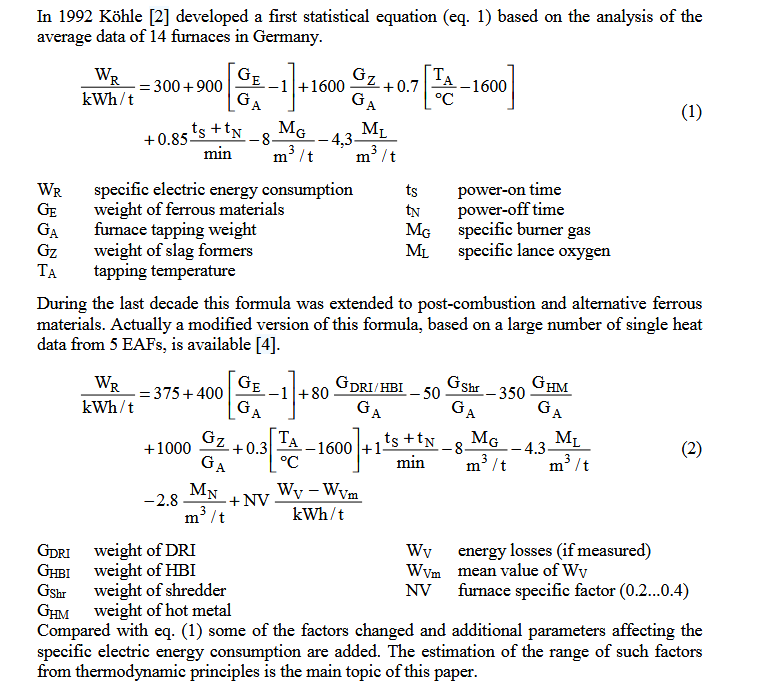

In [213]:
G_e = df_combined["Scrap"] + df_combined["OBM"]
G_dri = df_combined["OBM"]
G_z = (
    df_combined["Dolomite"]
    + df_combined["In-house produced lime"]
    + df_combined["Lime"]
    + df_combined["Lime, grade 2"]
    + df_combined["Magma"]
    + df_combined["Magma-P"]
    + df_combined["Magnesite brick scrap"]
)
# G_a = NOMINAL_TAPPING_WEIGHT * 1000
T_a = df_combined["TEMP"]
G_shr = df_combined["Separation scrap"]
G_hm = df_combined["Liquid scrap"]
t_s = df_combined['power_on']
t_n = df_combined['power_off']

G_a = (df_combined['Scrap'] * 0.9 / 1000 - G_z / 0.8 * 0.25 / 1000 + df_combined['OBM'] / 1000 * 0.9) * 1000

M_g = df_combined['GAS_AMOUNT'] / 0.8032 / G_a * 1000
M_l = df_combined['O2_AMOUNT'] / 1.43 / G_a * 1000

stat_MW = 375 + 400 * (G_e / G_a - 1) + 80 * G_dri / G_a - 350 * G_hm / G_a + 1000 * G_z / G_a + 0.3 * (T_a - 1600) + (t_s + t_n) - 8 * M_g - 4.3 * M_l

df_combined['stat_MW'] = stat_MW

Analysis of all the components of the formula:

In [214]:
# tap_mass = (df_combined['Scrap'] * 0.9 / 1000 - G_z / 0.8 * 0.25 / 1000 + df_combined['OBM'] / 1000 * 0.9)
df_combined['Calc_tap_mass'] = G_a / 1000

In [215]:
# df_combined = df_combined.rename(columns = lambda x:re.sub('[^A-Za-z0-9_]+', '_', x))

In [216]:
df_combined.shape

(20427, 71)

20326, 73

## Final data save

In [217]:
df_combined.to_csv('data/prepared/df_combined.csv')